In [1]:
# Necessary Libraries
import os
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import librosa.display
import torch
from torch.utils.data import Dataset
from sklearn.model_selection import train_test_split
from transformers import AutoFeatureExtractor
from tqdm import tqdm

warnings.filterwarnings("ignore")

c:\Users\Atul\anaconda3\envs\gpu_env\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Configs
DATA_ROOT  = "../data/messy_mashup/genres_stems"
TEST_DIR   = "../data/messy_mashup/mashups"
NOISE_DIR  = "../data/messy_mashup/ESC-50-master/audio"
MODEL_DIR  = "../models"
CACHE_DIR  = "../working/ast_cache"

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(CACHE_DIR, exist_ok=True)

GENRES = ["blues", "classical", "country", "disco", "hiphop",
          "jazz", "metal", "pop", "reggae", "rock"]
STEMS  = ["drums", "vocals", "bass", "other"]

GENRE_TO_IDX = {g: i for i, g in enumerate(GENRES)}
IDX_TO_GENRE = {i: g for g, i in GENRE_TO_IDX.items()}

# per-model audio config
SR_CRNN   = 22050
SR_AST    = 16000
DURATION  = 10.0          # seconds — more musical context than the 5s milestone default

# spectrogram config (CRNN)
N_MELS      = 128
N_FFT       = 2048
HOP_LENGTH  = 256          # finer temporal resolution vs milestone's 512

# augmentation config
GAIN_MIN        = 0.5
GAIN_MAX        = 1.5
STRETCH_MIN     = 0.85
STRETCH_MAX     = 1.15
SNR_MIN_DB      = 5.0
SNR_MAX_DB      = 20.0

# training config
SAMPLES_PER_GENRE = 200    # cross-song mixes generated per genre
VAL_SPLIT         = 0.2
BATCH_SIZE        = 32
DATA_SEED         = 67
TRAINING_SEED     = 1234

AST_MODEL_ID = "MIT/ast-finetuned-audioset-10-10-0.4593"

In [3]:
# Dataset structure

records = []
for genre in GENRES:
    genre_dir = os.path.join(DATA_ROOT, genre)
    songs = sorted(os.listdir(genre_dir))
    for song in songs:
        song_dir = os.path.join(genre_dir, song)
        present = [s for s in STEMS if os.path.exists(os.path.join(song_dir, f"{s}.wav"))]
        sizes   = {s: os.path.getsize(os.path.join(song_dir, f"{s}.wav")) / 1024
                   for s in present}
        records.append({
            "genre":    genre,
            "song":     song,
            "n_stems":  len(present),
            "complete": len(present) == 4,
            **{f"{s}_kb": sizes.get(s, 0) for s in STEMS}
        })

df_structure = pd.DataFrame(records)

print("Songs per genre:")
print(df_structure.groupby("genre")["song"].count().to_string())
print(f"\nTotal songs      : {len(df_structure)}")
print(f"Complete entries : {df_structure['complete'].sum()}")
print(f"Incomplete       : {(~df_structure['complete']).sum()}")
print(f"\nFiles below 4KB (likely corrupted):")
small = df_structure[
    (df_structure[[f"{s}_kb" for s in STEMS]] < 4).any(axis=1)
]
print(small[["genre", "song"]] if len(small) else "  None found")

Songs per genre:
genre
blues        100
classical    100
country      100
disco        100
hiphop       100
jazz         100
metal        100
pop          100
reggae       100
rock         100

Total songs      : 1000
Complete entries : 1000
Incomplete       : 0

Files below 4KB (likely corrupted):
  None found


In [4]:
# Duration and sample rate analysis
dur_records = []
for genre in GENRES:
    genre_dir = os.path.join(DATA_ROOT, genre)
    song = sorted(os.listdir(genre_dir))[0]
    for stem in STEMS:
        path = os.path.join(genre_dir, song, f"{stem}.wav")
        y, sr = librosa.load(path, sr=None)
        dur_records.append({
            "genre": genre, "stem": stem,
            "duration_s": round(len(y) / sr, 2), "sr": sr
        })

df_dur = pd.DataFrame(dur_records)
print("\nMean stem duration per genre (s):")
print(df_dur.groupby("genre")["duration_s"].mean().round(2).to_string())
print(f"\nSample rates in dataset: {sorted(df_dur['sr'].unique().tolist())}")


Mean stem duration per genre (s):
genre
blues        30.01
classical    30.01
country      30.08
disco        30.12
hiphop       30.00
jazz         30.01
metal        30.00
pop          30.00
reggae       30.01
rock         30.01

Sample rates in dataset: [44100]


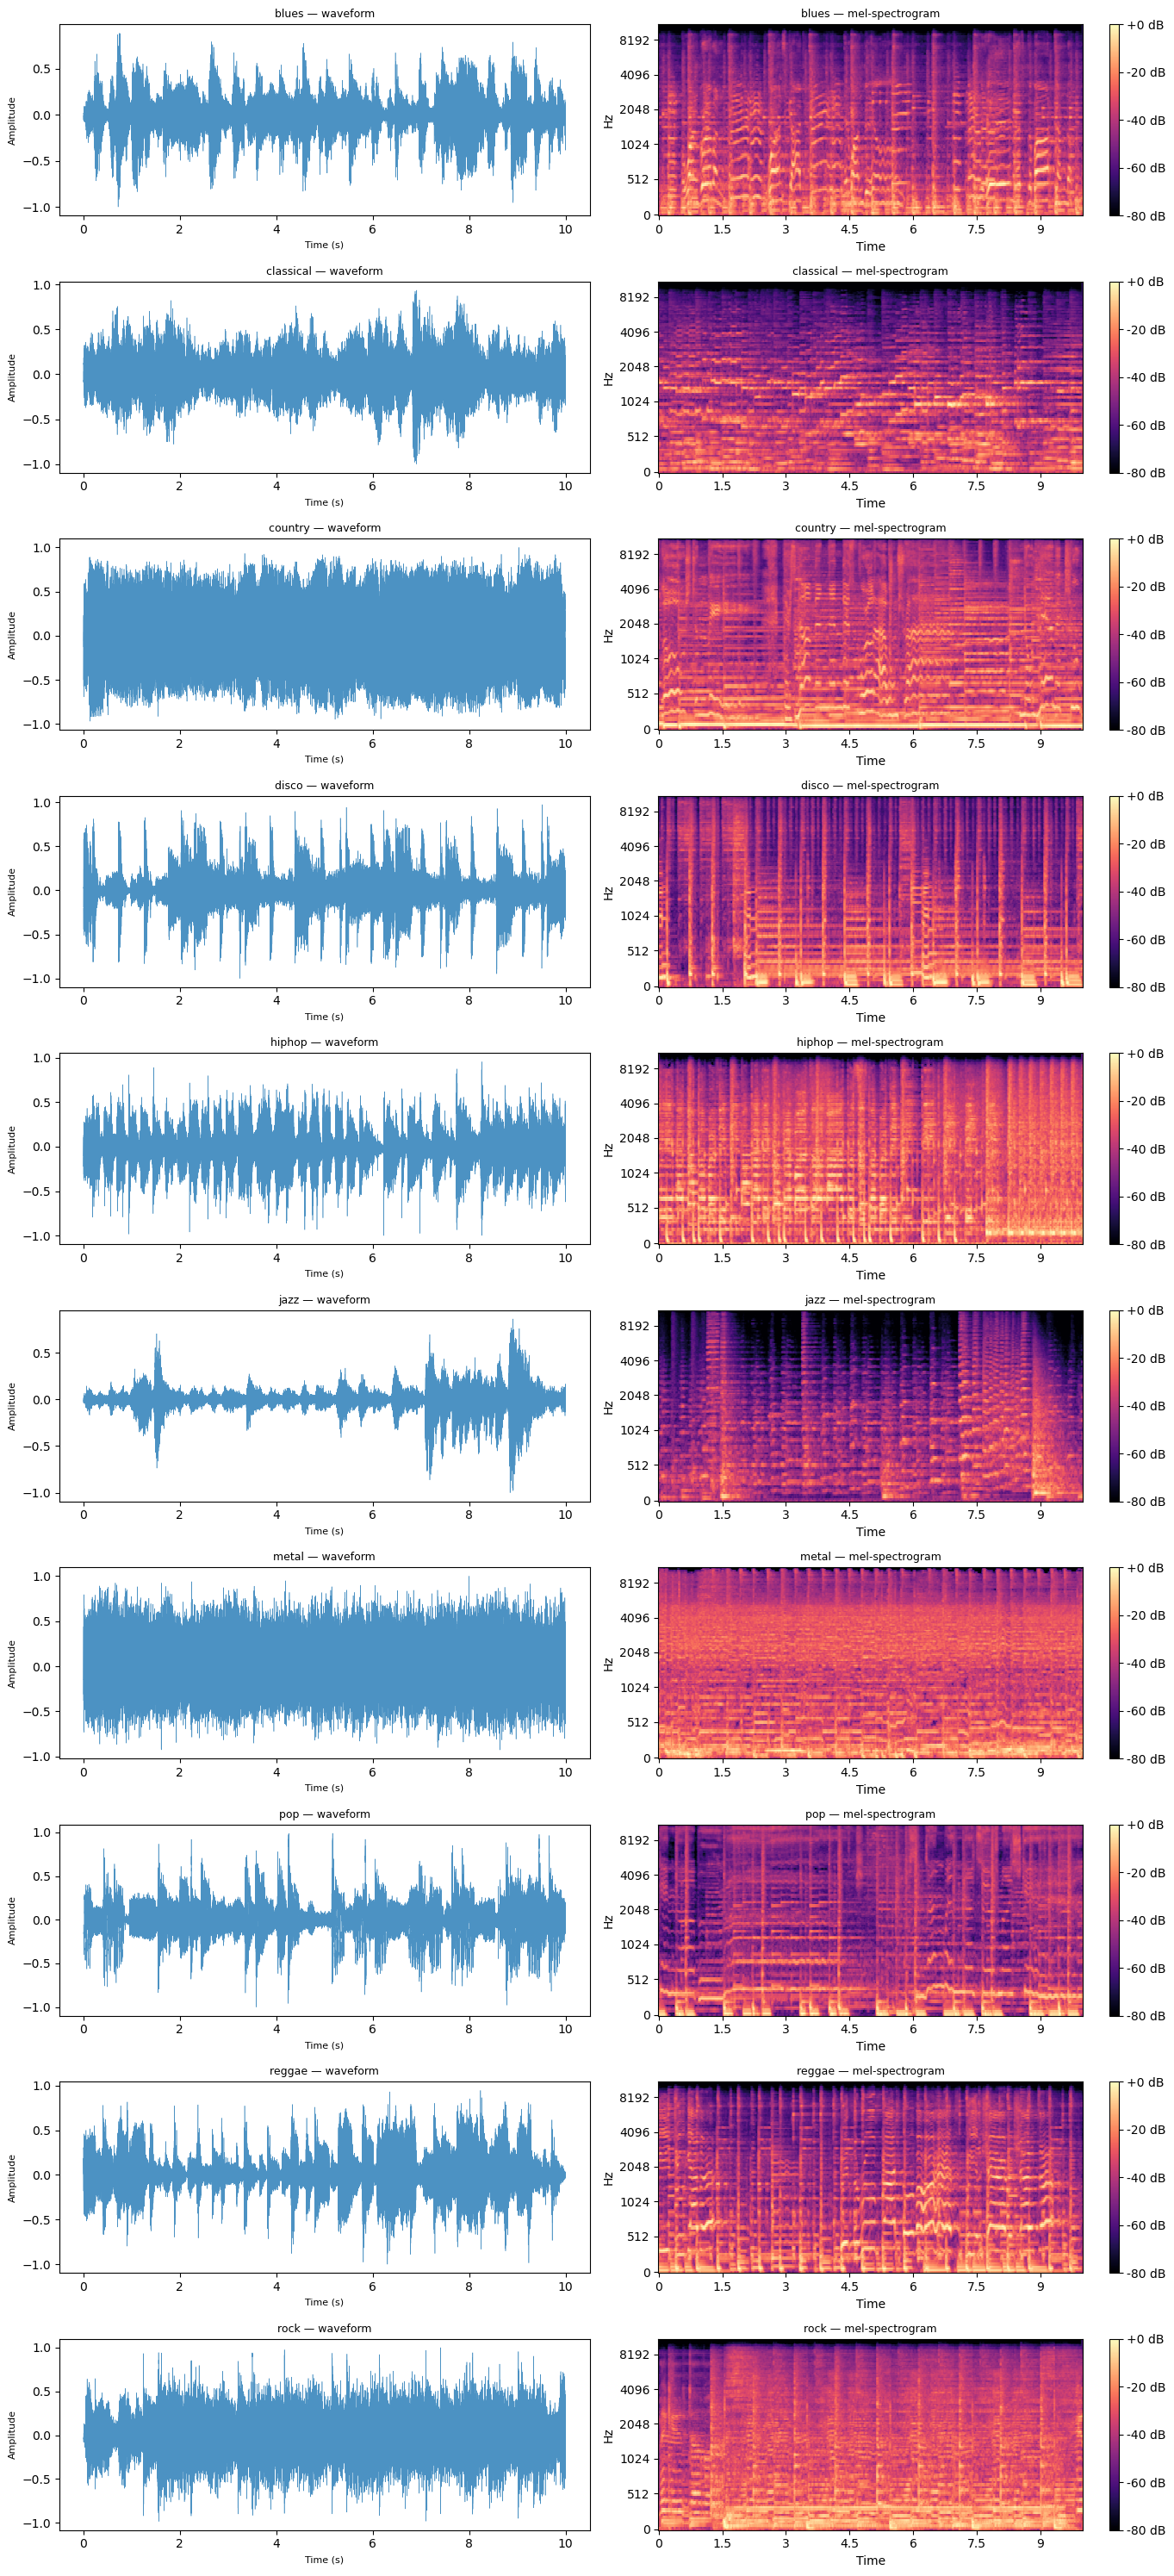

In [5]:
# Waveform and mel Spectogram per genre

def load_mix(genre, song_name, sr, duration):
    """Load and sum all 4 stems for a given song, then peak-normalise."""
    target_len = int(sr * duration)
    genre_dir  = os.path.join(DATA_ROOT, genre)
    mix        = np.zeros(target_len, dtype=np.float32)
    for stem in STEMS:
        path = os.path.join(genre_dir, song_name, f"{stem}.wav")
        try:
            y, _ = librosa.load(path, sr=sr, duration=duration)
            y    = np.pad(y, (0, max(0, target_len - len(y))))[:target_len]
            mix += y
        except Exception:
            pass
    peak = np.max(np.abs(mix))
    if peak > 0:
        mix /= (peak + 1e-9)
    return mix


fig, axes = plt.subplots(len(GENRES), 2, figsize=(14, 3 * len(GENRES)))
for i, genre in enumerate(GENRES):
    song = sorted(os.listdir(os.path.join(DATA_ROOT, genre)))[0]
    mix  = load_mix(genre, song, SR_CRNN, DURATION)

    # waveform
    t = np.linspace(0, DURATION, len(mix))
    axes[i, 0].plot(t, mix, linewidth=0.4, alpha=0.8)
    axes[i, 0].set_title(f"{genre} — waveform", fontsize=9)
    axes[i, 0].set_xlabel("Time (s)", fontsize=8)
    axes[i, 0].set_ylabel("Amplitude", fontsize=8)

    # mel-spectrogram
    S    = librosa.feature.melspectrogram(y=mix, sr=SR_CRNN, n_mels=N_MELS,
                                          n_fft=N_FFT, hop_length=HOP_LENGTH)
    S_db = librosa.power_to_db(S, ref=np.max)
    img  = librosa.display.specshow(S_db, sr=SR_CRNN, hop_length=HOP_LENGTH,
                                    x_axis="time", y_axis="mel", ax=axes[i, 1])
    axes[i, 1].set_title(f"{genre} — mel-spectrogram", fontsize=9)
    plt.colorbar(img, ax=axes[i, 1], format="%+2.0f dB")

plt.tight_layout()
plt.savefig(os.path.join(MODEL_DIR, "eda_waveforms_melspecs.png"), dpi=80, bbox_inches="tight")
plt.show()



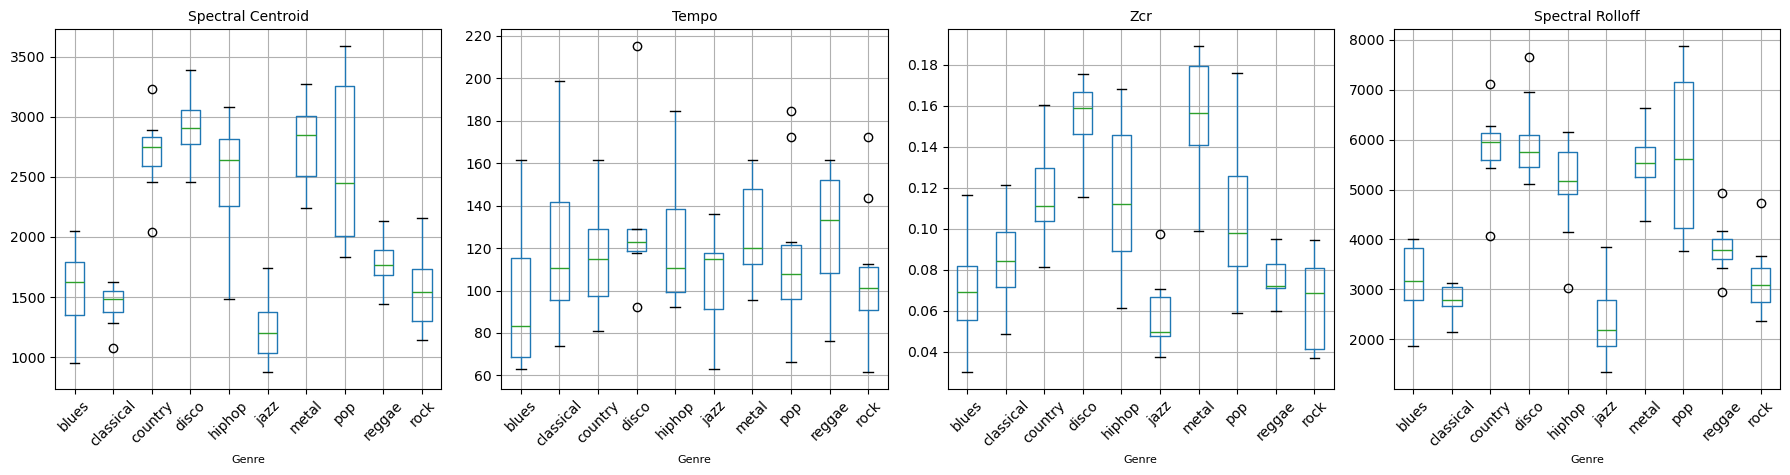


Mean spectral features per genre:
           spectral_centroid   tempo   zcr
genre                                     
blues                1561.73   94.84  0.07
classical            1444.17  119.71  0.08
country              2696.76  114.21  0.12
disco                2927.62  129.93  0.15
hiphop               2486.41  123.10  0.12
jazz                 1257.33  105.66  0.06
metal                2776.08  125.81  0.16
pop                  2598.77  116.22  0.10
reggae               1780.40  129.17  0.08
rock                 1547.49  106.09  0.06


In [6]:
# Spectral feature comparison across genres
feat_records = []
for genre in GENRES:
    genre_dir = os.path.join(DATA_ROOT, genre)
    songs     = sorted(os.listdir(genre_dir))[:10]
    for song in songs:
        mix = load_mix(genre, song, SR_CRNN, DURATION)
        centroid  = librosa.feature.spectral_centroid(y=mix, sr=SR_CRNN).mean()
        bandwidth = librosa.feature.spectral_bandwidth(y=mix, sr=SR_CRNN).mean()
        rolloff   = librosa.feature.spectral_rolloff(y=mix, sr=SR_CRNN).mean()
        zcr       = librosa.feature.zero_crossing_rate(mix).mean()
        tempo, _  = librosa.beat.beat_track(y=mix, sr=SR_CRNN)
        feat_records.append({
            "genre":             genre,
            "spectral_centroid": centroid,
            "spectral_bandwidth": bandwidth,
            "spectral_rolloff":  rolloff,
            "zcr":               zcr,
            "tempo":             float(tempo)
        })

df_feat = pd.DataFrame(feat_records)

features_to_plot = ["spectral_centroid", "tempo", "zcr", "spectral_rolloff"]
fig, axes = plt.subplots(1, len(features_to_plot), figsize=(18, 5))
for ax, feat in zip(axes, features_to_plot):
    df_feat.boxplot(column=feat, by="genre", ax=ax)
    ax.set_title(feat.replace("_", " ").title(), fontsize=10)
    ax.set_xlabel("Genre", fontsize=8)
    ax.tick_params(axis="x", rotation=45)
plt.suptitle("")
plt.tight_layout()
plt.savefig(os.path.join(MODEL_DIR, "eda_spectral_features.png"), dpi=80, bbox_inches="tight")
plt.show()

print("\nMean spectral features per genre:")
print(df_feat.groupby("genre")[["spectral_centroid", "tempo", "zcr"]].mean().round(2).to_string())


Train mix  — mean mel energy (dB): -40.41 ± 5.81
Test mashup — mean mel energy (dB): -41.29 ± 5.13


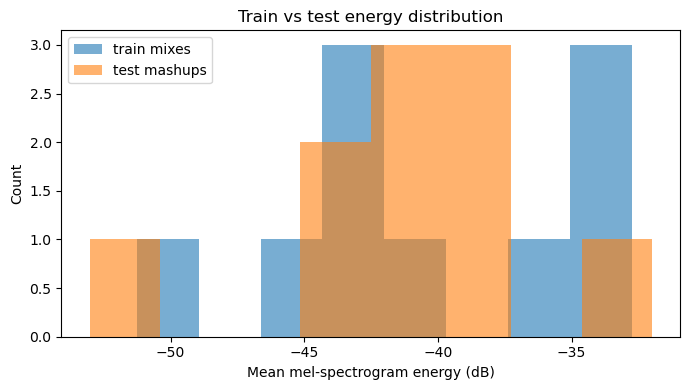

In [7]:
# train mix vs test mashup — distribution gap check

n_samples = 10
train_energies, test_energies = [], []

for genre in random.Random(DATA_SEED).sample(GENRES, n_samples):
    genre_dir = os.path.join(DATA_ROOT, genre)
    song      = sorted(os.listdir(genre_dir))[0]
    mix       = load_mix(genre, song, SR_CRNN, DURATION)
    S         = librosa.feature.melspectrogram(y=mix, sr=SR_CRNN, n_mels=N_MELS,
                                               n_fft=N_FFT, hop_length=HOP_LENGTH)
    train_energies.append(librosa.power_to_db(S, ref=np.max).mean())

test_files = sorted(os.listdir(TEST_DIR))[:n_samples]
for fname in test_files:
    try:
        y, _ = librosa.load(os.path.join(TEST_DIR, fname), sr=SR_CRNN, duration=DURATION)
        S    = librosa.feature.melspectrogram(y=y, sr=SR_CRNN, n_mels=N_MELS,
                                              n_fft=N_FFT, hop_length=HOP_LENGTH)
        test_energies.append(librosa.power_to_db(S, ref=np.max).mean())
    except Exception:
        pass

print(f"\nTrain mix  — mean mel energy (dB): {np.mean(train_energies):.2f} ± {np.std(train_energies):.2f}")
print(f"Test mashup — mean mel energy (dB): {np.mean(test_energies):.2f} ± {np.std(test_energies):.2f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(train_energies, bins=8, alpha=0.6, label="train mixes")
ax.hist(test_energies,  bins=8, alpha=0.6, label="test mashups")
ax.set_xlabel("Mean mel-spectrogram energy (dB)")
ax.set_ylabel("Count")
ax.set_title("Train vs test energy distribution")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(MODEL_DIR, "eda_train_vs_test.png"), dpi=80, bbox_inches="tight")
plt.show()

In [8]:
# Augmentation utilities

def _pad_or_trim(y, target_len):
    if len(y) >= target_len:
        return y[:target_len]
    return np.pad(y, (0, target_len - len(y)))


def make_augmented_mix(genre, data_root, sr, duration, rng):
    """
    Build one training sample via cross-song stem mixing.
    Each of the 4 stems is drawn from a independently chosen song of the
    same genre, simulating the cross-song recombination in the test mashups.
    Per-stem random gain, time-stretch, and variable-SNR ESC-50 noise are
    applied before peak normalisation.
    """
    target_len = int(sr * duration)
    genre_dir  = os.path.join(data_root, genre)
    songs      = sorted(os.listdir(genre_dir))
    mix        = np.zeros(target_len, dtype=np.float32)

    for stem in STEMS:
        song = rng.choice(songs)
        path = os.path.join(genre_dir, song, f"{stem}.wav")
        try:
            y, _ = librosa.load(path, sr=sr)
            # random crop if stem is longer than target
            if len(y) > target_len:
                start = rng.randint(0, len(y) - target_len)
                y     = y[start: start + target_len]
            else:
                y = _pad_or_trim(y, target_len)
            gain  = rng.uniform(GAIN_MIN, GAIN_MAX)
            mix  += y * gain
        except Exception:
            pass

    # time-stretch the full mix
    rate = rng.uniform(STRETCH_MIN, STRETCH_MAX)
    try:
        mix = librosa.effects.time_stretch(mix, rate=rate)
    except Exception:
        pass
    mix = _pad_or_trim(mix, target_len)

    # add ESC-50 noise at a random SNR
    noise_files = [f for f in os.listdir(NOISE_DIR) if f.endswith(".wav")]
    try:
        noise, _ = librosa.load(
            os.path.join(NOISE_DIR, rng.choice(noise_files)), sr=sr
        )
        noise       = _pad_or_trim(noise, target_len)
        snr_db      = rng.uniform(SNR_MIN_DB, SNR_MAX_DB)
        sig_rms     = np.sqrt(np.mean(mix   ** 2)) + 1e-9
        noise_rms   = np.sqrt(np.mean(noise ** 2)) + 1e-9
        target_rms  = sig_rms / (10 ** (snr_db / 20.0))
        mix         = mix + noise * (target_rms / noise_rms)
    except Exception:
        pass

    peak = np.max(np.abs(mix))
    if peak > 0:
        mix /= (peak + 1e-9)
    return mix

In [9]:
# Dataset classes

class GenreDatasetCRNN(Dataset):
    """
    Generates augmented mel-spectrogram tensors for CRNN training.
    Each __getitem__ call builds a fresh cross-song mix on the fly.
    """

    def __init__(self, genres, data_root, sr, duration, n_mels, n_fft, hop_length,
                 samples_per_genre=SAMPLES_PER_GENRE, seed=TRAINING_SEED):
        self.genres           = genres
        self.data_root        = data_root
        self.sr               = sr
        self.duration         = duration
        self.n_mels           = n_mels
        self.n_fft            = n_fft
        self.hop_length       = hop_length
        self.samples_per_genre = samples_per_genre
        self.seed             = seed
        # each item is (genre, sample_index) — index drives the rng seed
        self.items = [(g, i) for g in genres for i in range(samples_per_genre)]

    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx):
        genre, sample_idx = self.items[idx]
        rng = random.Random(self.seed + idx)
        mix = make_augmented_mix(genre, self.data_root, self.sr, self.duration, rng)

        S    = librosa.feature.melspectrogram(
            y=mix, sr=self.sr, n_mels=self.n_mels,
            n_fft=self.n_fft, hop_length=self.hop_length
        )
        S_db = librosa.power_to_db(S, ref=np.max).astype(np.float32)
        # min-max normalise to [0, 1]
        S_db = (S_db - S_db.min()) / (S_db.max() - S_db.min() + 1e-9)
        return torch.tensor(S_db).unsqueeze(0), GENRE_TO_IDX[genre]


class PrecomputedASTDataset(Dataset):
    """
    Loads precomputed AST feature tensors from disk.
    Precomputation is done once via precompute_ast_features() below.
    """

    def __init__(self, cache_dir, split):
        self.split_dir = os.path.join(cache_dir, split)
        self.files     = sorted(os.listdir(self.split_dir))

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        fpath          = os.path.join(self.split_dir, self.files[idx])
        data           = torch.load(fpath, weights_only=True)
        return data["input_values"], data["label"]

In [10]:
# AST feature precomputation

def precompute_ast_features(data_root, cache_dir, genres, sr, duration,
                             samples_per_genre=SAMPLES_PER_GENRE,
                             val_split=VAL_SPLIT, seed=TRAINING_SEED):
    """
    Generates augmented audio mixes, runs the AST feature extractor, and
    saves each result to disk. This avoids repeating the extraction step
    each training epoch.
    """
    feature_extractor = AutoFeatureExtractor.from_pretrained(AST_MODEL_ID)

    all_items = [(g, i) for g in genres for i in range(samples_per_genre)]
    train_items, val_items = train_test_split(
        all_items, test_size=val_split, random_state=seed,
        stratify=[g for g, _ in all_items]
    )

    for split, items in [("train", train_items), ("val", val_items)]:
        split_dir = os.path.join(cache_dir, split)
        os.makedirs(split_dir, exist_ok=True)
        for pos, (genre, idx) in enumerate(tqdm(items, desc=f"Precomputing [{split}]")):
            out_path = os.path.join(split_dir, f"{split}_{pos:05d}.pt")
            if os.path.exists(out_path):
                continue
            rng = random.Random(seed + pos)
            mix = make_augmented_mix(genre, data_root, sr, duration, rng)
            inputs = feature_extractor(
                mix, sampling_rate=sr, return_tensors="pt", padding=True
            )
            torch.save({
                "input_values": inputs["input_values"].squeeze(0),
                "label":        GENRE_TO_IDX[genre]
            }, out_path)
    print("Precomputation complete.")


# run precomputation (skips if cache already populated)
if not os.path.exists(os.path.join(CACHE_DIR, "train")) or \
        len(os.listdir(os.path.join(CACHE_DIR, "train"))) == 0:
    precompute_ast_features(
        data_root=DATA_ROOT, cache_dir=CACHE_DIR, genres=GENRES,
        sr=SR_AST, duration=DURATION
    )
else:
    print("AST feature cache already exists, skipping precomputation.")

Precomputing [val]: 100%|██████████| 400/400 [01:29<00:00,  4.47it/s]

Precomputation complete.
